In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = {
    'text': [
        "Government announces new education policy for schools",
        "Scientists publish research on climate change",
        "Local authorities announce new public transport rules",
        "University announces new examination schedule",
        "Government launches new healthcare program",
        "Researchers develop a new renewable energy technology",
        "City administration announces road safety measures",
        "Education department releases official scholarship guidelines",

        "Scientists confirm that drinking water makes people invisible",
        "Government announces that humans no longer need sleep",
        "Eating one fruit can make people live for 500 years",
        "Aliens officially take control of the government",
        "Researchers discover that phones can read human thoughts",
        "Government declares that gravity will stop working tomorrow",
        "A secret pill can make anyone instantly intelligent",
        "Scientists announce that the moon is made entirely of cheese"
    ],

    'label': [
        'REAL',
        'REAL',
        'REAL',
        'REAL',
        'REAL',
        'REAL',
        'REAL',
        'REAL',

        'FAKE',
        'FAKE',
        'FAKE',
        'FAKE',
        'FAKE',
        'FAKE',
        'FAKE',
        'FAKE'
    ]
}

df = pd.DataFrame(data)

df

,text,label
0,Government announces new education policy for ...,REAL
1,Scientists publish research on climate change,REAL
2,Local authorities announce new public transpor...,REAL
3,University announces new examination schedule,REAL
4,Government launches new healthcare program,REAL
5,Researchers develop a new renewable energy tec...,REAL
6,City administration announces road safety meas...,REAL
7,Education department releases official scholar...,REAL
8,Scientists confirm that drinking water makes p...,FAKE
9,Government announces that humans no longer nee...,FAKE


In [3]:
print("Number of news articles:", len(df))
print("\nClass distribution:")
print(df['label'].value_counts())

Number of news articles: 16

Class distribution:
label
REAL    8
FAKE    8
Name: count, dtype: int64


In [4]:
X = df['text']
y = df['label']

print("Input: News text")
print("Output: FAKE or REAL")

Input: News text
Output: FAKE or REAL


In [5]:
vectorizer = TfidfVectorizer()

X_tfidf = vectorizer.fit_transform(X)

print("Original text samples:", X.shape[0])
print("TF-IDF matrix shape:", X_tfidf.shape)

Original text samples: 16
TF-IDF matrix shape: (16, 87)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 12
Testing samples: 4


In [7]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Fake News Detection model trained successfully.")

Fake News Detection model trained successfully.


In [8]:
y_pred = model.predict(X_test)

print("Actual labels:")
print(y_test.values)

print("\nPredicted labels:")
print(y_pred)

Actual labels:
['FAKE' 'REAL' 'FAKE' 'REAL']

Predicted labels:
['FAKE' 'FAKE' 'FAKE' 'REAL']


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.75
Accuracy Percentage: 75.0 %


In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['FAKE', 'REAL']
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2 0]
 [1 1]]


In [11]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred
    )
)

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.67      1.00      0.80         2
        REAL       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



In [12]:
new_news = [
    "Government announces a new education program for students"
]

new_news_tfidf = vectorizer.transform(new_news)

prediction = model.predict(new_news_tfidf)

print("News:")
print(new_news[0])

print("\nPrediction:")
print(prediction[0])

News:
Government announces a new education program for students

Prediction:
REAL


In [13]:
new_news = [
    "Scientists announce that humans can survive without oxygen"
]

new_news_tfidf = vectorizer.transform(new_news)

prediction = model.predict(new_news_tfidf)

print("News:")
print(new_news[0])

print("\nPrediction:")
print(prediction[0])

News:
Scientists announce that humans can survive without oxygen

Prediction:
FAKE


In [14]:
probabilities = model.predict_proba(new_news_tfidf)

print("Prediction:", prediction[0])
print("Confidence:", max(probabilities[0]) * 100, "%")

Prediction: FAKE
Confidence: 60.94098574039653 %


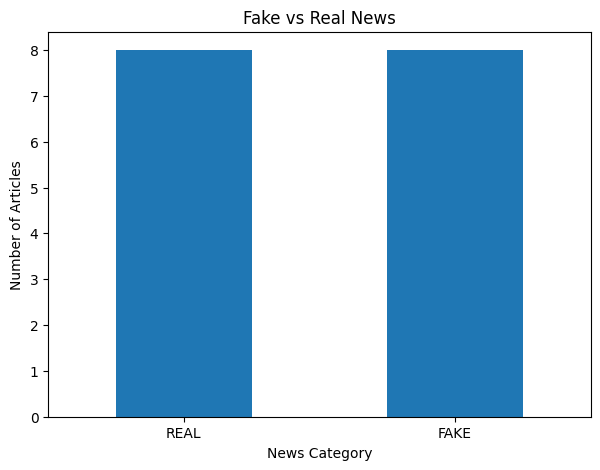

In [15]:
import matplotlib.pyplot as plt

df['label'].value_counts().plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Fake vs Real News')
plt.xlabel('News Category')
plt.ylabel('Number of Articles')
plt.xticks(rotation=0)

plt.show()